# Una inversión ERT topográfica con control sintético conocido

**Pregunta:** ¿Predice el solver topográfico M07 mediciones reservadas en el caso sintético?

**Nivel 3 — Experimento con el solver**  
**Prerrequisitos:** geometría Wenner, resistividad logarítmica, regularización y validación retenida; 60–90 min incluyendo el cálculo.



## Objetivos

¿Cuánto cambia el campo de potencial por un conductor lateralmente acotado? ¿La inversión 2D con topografía predice mediciones que no ajustó? ¿Cuánto varían el modelo y los errores retenidos al cambiar la malla o los errores supuestos?



## Preparación

Instala los pins exactos del notebook con `pip install numpy==2.2.6 matplotlib==3.10.8` y luego el motor aislado y fijado: `./scripts/setup.ps1 -Notebooks` y `./scripts/setup.ps1 -Ert` (Windows), o `scripts/setup.sh --notebooks` y `scripts/setup.sh --ert`. pyGIMLi requiere NumPy 2.5.3; queda aislado del NumPy 2.2.6 del entorno principal.



Defina `CAOS_TEMP_ROOT` en su shell como directorio temporal absoluto y local al dispositivo antes de invocar `scripts/run_notebooks.py`. El runner usa ese valor configurado; no selecciona ni incrusta una ruta específica de máquina. Si falta la variable, la celda del método se detiene con una instrucción directa.

## Datos

El recibo versionado y verificado por SHA-256 fue generado por el script determinista. Cambia `RUN_SOLVER=True` en la celda experimental para repetir el cálculo con el entorno aislado `.venv-ert`. El script genera el perfil Wenner de 28 electrodos y cuatro separaciones. Los electrodos siguen una superficie curva; pyGIMLi calcula las respuestas para un fondo de 100 Ω m con un cuerpo finito de 25 Ω m. Se aplica una perturbación log-normal de 1% con semilla fija. Son observaciones simuladas con verdad explícita, nunca los datos restringidos de Slagdump.


## Método

Las resistencias sintéticas provienen de una solución de elementos finitos 2D de la ecuación de conductividad DC, con elevaciones reales de electrodos y un cuerpo conductor finito. La inversión usa el administrador ERT de pyGIMLi, factores geométricos numéricos con topografía, un modelo de resistividad logarítmica y los parámetros fijados del repositorio. La partición principal retiene cada quinta medición dentro de cada separación AB; el segundo ajuste retiene los cuadrupolos cuyo punto medio AB cae en el 40–60% central del perfil.

El objetivo de entrenamiento combina desajuste ponderado y regularización de suavidad. Los pesos usan el error supuesto documentado de 3% en resistencia; no se presenta como calibración instrumental. El experimento repite el ajuste con una malla de parámetros alternativa y con errores supuestos duplicados. Son controles de sensibilidad; no seleccionan un modelo mejor. Revisa la implementación y el criterio de parada condicional en `data-pipeline/ert.py`.
### Verdad generada M07 y particiones

El control fresco por elementos finitos tiene verdad conocida y dos geometrías retenidas; ninguna partición contiene observaciones Slagdump.


In [1]:
from pathlib import Path
from importlib.metadata import version

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Verifique el registro de fuentes y la presencia local de entradas ERT crudas.
import json
from pathlib import Path

ledger = json.loads((root / "data/source-ledger.json").read_text(encoding="utf-8"))
print("el registro menciona Slagdump:", "slagdump" in json.dumps(ledger).lower())
raw = list((root / "data").rglob("*.ohm"))
print("Archivos .ohm locales:", raw, "; inversión posible con datos de campo:", bool(raw))


Versiones del entorno: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
el registro menciona Slagdump: True
Archivos .ohm locales: [] ; inversión posible con datos de campo: False


### Experimento controlado de QC y geometría

Construye en memoria un sondeo Wenner `.ohm` **sintético** con elevaciones conocidas, respuesta nominal de semiespacio plano, dispersión con semilla fija y un valor atípico. Ejecuta el parser del repositorio, QC que solo marca, factores geométricos y validación predefinida. El factor ignora deliberadamente la elevación: compara la resistividad aparente diagnóstica con el relieve y explica por qué esto **no** es corrección topográfica ni inversión. No se infieren datos de terreno ni geología.

Las entradas y salidas son sintéticas; la marca conserva la medición y el factor plano es solo diagnóstico.

### Defina adquisición Wenner sintética y bytes de fuente estrictos

In [2]:
# Defina la superficie sintética y las filas ABMN del arreglo Wenner.
import sys

sys.path.insert(0, str(root / "data-pipeline"))
import ert
import numpy as np
import matplotlib.pyplot as plt

ne = 16
x = np.arange(ne, dtype=float) * 2.0
z = 0.45 * np.sin(x / 7.0) + 0.012 * x
rows = []
for spacing in (1, 2, 3):
    for start in range(ne - 3 * spacing):
        rows.append(
            (
                start + 1,
                start + 1 + 3 * spacing,
                start + 1 + spacing,
                start + 1 + 2 * spacing,
            )
        )




### Serializar el formato del levantamiento sintético

La superficie de electrodos y las geometrías Wenner ABMN sin solapamiento quedan como arreglos explícitos. El paso siguiente las codifica en el formato de texto documentado para que el parser y los métodos de inversión reciban la misma representación del pipeline.

In [3]:
# Serializar el formato del levantamiento sintético.
def source_bytes(resistance):
    header = [
        "# Synthetic teaching fixture; not field data",
        "# Wenner array; x/z in m; resistance in ohm",
        f"{ne}# Number of sensors",
        "#x z",
    ]
    sensors = [f"{xx:.6f} {zz:.6f}" for xx, zz in zip(x, z)]
    data_header = [f"{len(rows)}# Number of data", "#a b m n R"]
    measurements = [f"{a} {b} {m} {n} {value:.12g}" for (a, b, m, n), value in zip(rows, resistance)]
    return ("\n".join(header + sensors + data_header + measurements) + "\n").encode()


### Parsee, marque y separe lecturas sintéticas

In [4]:
# Analice las mediciones sintéticas con ruido y ejecute el control de calidad y la partición retenida del producto.
base = ert.parse_ohm_bytes(source_bytes(np.ones(len(rows))))
factors_base = ert.flat_halfspace_factors(base)
rng = np.random.default_rng(20261027)
resistance = 100.0 / factors_base * np.exp(rng.normal(0, 0.025, len(rows)))
outlier = min(5, len(resistance) - 1)
resistance[outlier] *= 12
s = ert.parse_ohm_bytes(source_bytes(resistance))
report = ert.qc(s)
train, held = ert.holdout_indices(s)
app = ert.flat_halfspace_factors(s) * s.resistance_ohm
print("electrodos y mediciones", report["sensor_count"], report["measurement_count"])
print("relieve y filas marcadas", report["topographic_relief_m"], report["flagged_rows"])
print("fila contaminada retenida", outlier in range(len(resistance)))
print("entrenamiento y reserva", len(train), len(held))
print("mediana de resistividad aparente Ω·m", float(np.median(app)))


electrodos y mediciones 16 30
relieve y filas marcadas 0.639031 [5]
fila contaminada retenida True
entrenamiento y reserva 25 5
mediana de resistividad aparente Ω·m 99.07252512562991


### Inspeccione geometría y diagnóstico de resistividad aparente

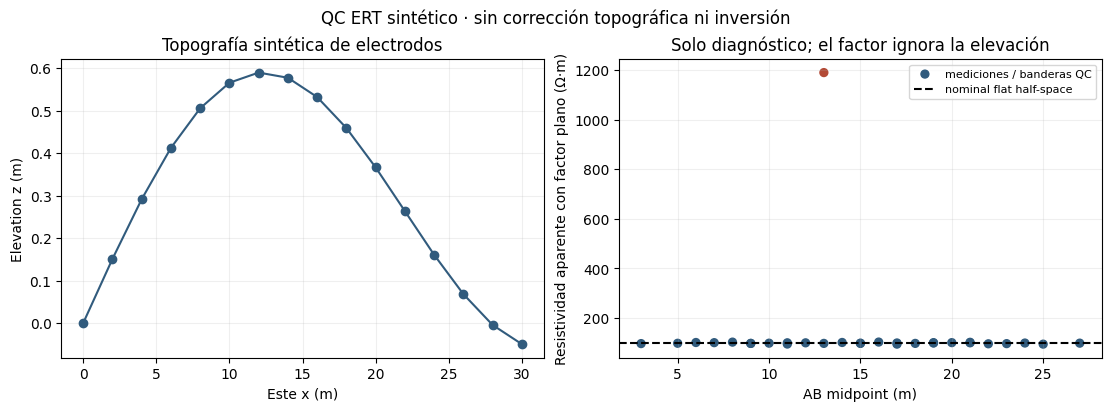

In [5]:
# Grafique el perfil sintético de electrodos y las lecturas de resistividad aparente con sus banderas.
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax[0].plot(x, z, "o-", color="#315b7d")
ax[0].set(xlabel="Este x (m)", ylabel="Elevation z (m)", title="Topografía sintética de electrodos")
ax[0].grid(alpha=0.2)
midpoint = (x[s.abmn[:, 0]] + x[s.abmn[:, 1]]) / 2
flagged = np.isin(np.arange(len(app)), report["flagged_rows"])
colors = np.where(flagged, "#b34a36", "#315b7d")
ax[1].scatter(midpoint, app, c=colors, s=32, label="mediciones / banderas QC")
ax[1].axhline(100, color="black", ls="--", label="nominal flat half-space")
ax[1].set(
    xlabel="AB midpoint (m)",
    ylabel="Resistividad aparente con factor plano (Ω·m)",
    title="Solo diagnóstico; el factor ignora la elevación",
)
ax[1].grid(alpha=0.2)
ax[1].legend(fontsize=8)
fig.suptitle("QC ERT sintético · sin corrección topográfica ni inversión")
plt.show()


### Inspeccionar la línea sintética de electrodos

La superficie y las posiciones Wenner graficadas definen topografía y geometría de adquisición usadas para generar datos sintéticos por elementos finitos. La figura puede revelar errores de índice o elevación antes de invertir. No contiene coordenadas ni resistencias de Slagdump, por lo que no establece cobertura ni permite una pseudosección de campo.


### Transformación a resistividad aparente

Aplique el factor geométrico del producto e inspeccione las lecturas por apertura del arreglo.

resistividad aparente Ω·m 94.84698797827475 99.07252512562991 1190.0751922800011


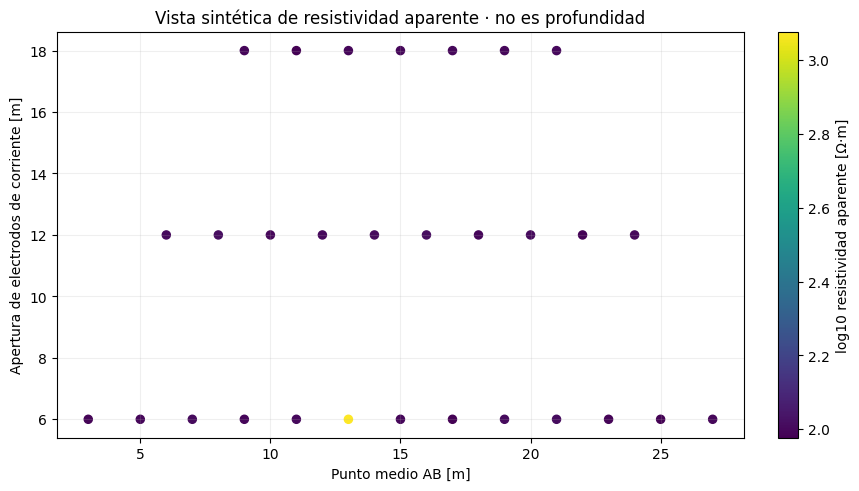

In [6]:
# Calcule resistividad aparente desde resistencia parseada y factores geométricos del producto.
import matplotlib.pyplot as plt

factors = ert.flat_halfspace_factors(s)
rho_app = factors * s.resistance_ohm
ab = s.abmn
x = s.sensors_xz_m[:, 0]
midpoint = (x[ab[:, 0]] + x[ab[:, 1]]) / 2
span = x[ab[:, 1]] - x[ab[:, 0]]
fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
points = ax.scatter(midpoint, span, c=np.log10(rho_app), cmap="viridis", s=34)
fig.colorbar(points, ax=ax, label="log10 resistividad aparente [Ω·m]")
ax.set(
    xlabel="Punto medio AB [m]",
    ylabel="Apertura de electrodos de corriente [m]",
    title="Vista sintética de resistividad aparente · no es profundidad",
)
ax.grid(alpha=0.2)
print("resistividad aparente Ω·m", float(rho_app.min()), float(np.median(rho_app)), float(rho_app.max()))
plt.show()


El factor geométrico transforma cada resistencia sintética a resistividad aparente bajo la aproximación de semiespacio plano y homogéneo. La vista apertura–punto medio muestra cómo varían escala y posición del arreglo a lo largo de la línea topográfica; no es una imagen de profundidad. Como el cuerpo verdadero es finito y la superficie irregular, no debe leerse como valor de celda ni como evidencia Slagdump.


La figura muestra cantidades calculadas en las unidades de sus ejes. Permite comparar la respuesta o diagnóstico bajo los supuestos declarados, pero no establece verdad de campo, unicidad geológica ni derechos de fuente. Interprete los valores numéricos impresos junto al patrón visual; la semejanza de curvas por sí sola no valida el método.
### Experiment — run the forward and inverse solvers

In [7]:
import os
# Ejecute ahora el pipeline M07 aislado; la salida se genera en esta ejecución.
import hashlib, json, os, subprocess
from pathlib import Path

try:
    temp_root_value = os.environ["CAOS_TEMP_ROOT"]
except KeyError as error:
    raise RuntimeError(
        "Defina CAOS_TEMP_ROOT con la raíz temporal configurada para este dispositivo y vuelva a ejecutar scripts/run_notebooks.py."
    ) from error
temp_root = Path(temp_root_value).expanduser()
if not temp_root.is_absolute():
    raise RuntimeError("CAOS_TEMP_ROOT debe ser una ruta absoluta local de este dispositivo.")
work = temp_root / "caos-geophysics-ert-notebook"
work.mkdir(parents=True, exist_ok=True)
output = work / "m07-current-run.json"
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = engine_root / ".venv-ert" / "Scripts" / "python.exe"
if not engine.is_file():
    engine = engine_root / ".venv-ert" / "bin" / "python"
if not engine.is_file():
    raise RuntimeError("Prepare el entorno aislado de pyGIMLi con scripts/setup.ps1 -Ert")
command = [str(engine), str(root / "data-pipeline" / "ert_synthetic_experiment.py"), "--output", str(output)]


### Ejecutar el experimento pyGIMLi fijado

El comando usa el entorno aislado del solver y escribe un recibo nuevo bajo la raíz configurada por quien ejecuta. El JSON se comprueba contra la identidad sintética esperada y se resume con su hash y puntajes de validación independientes.

In [8]:
# Ejecutar el experimento pyGIMLi fijado.
completed = subprocess.run(command, cwd=root, capture_output=True, text=True, timeout=600)
if completed.returncode:
    raise RuntimeError(completed.stdout + "\n" + completed.stderr[-4000:])
payload = output.read_bytes()
experiment = json.loads(payload)
assert experiment["source_id"] == "original-synthetic-ert-control"
assert experiment["experiment"]["is_field_data"] is False
print("SHA-256 de entrada sintética:", experiment["source_sha256"])
print("estado:", experiment["inverse_status"], "mediciones:", experiment["qc"]["measurement_count"])
print("RMSE log-R retenido intercalado =", round(experiment["inverse"]["heldout_log_r_rmse"], 3))
print("RMSE log-R retenido por bloques espaciales =", round(experiment["blocked_validation"]["heldout_log_r_rmse"], 3))


SHA-256 de entrada sintética: 7d0851c20feea718493b62dd9c1c5b71fdbf364fbe46982d881e7fc93ae62316
estado: passed mediciones: 82
RMSE log-R retenido intercalado = 0.031
RMSE log-R retenido por bloques espaciales = 0.066


### Comparar la verdad, el modelo recuperado, la cobertura y los residuales

In [9]:
# Prepare los arreglos del solver, las coordenadas de malla y la partición exacta de validación.
import numpy as np
from matplotlib.tri import Triangulation
inv = experiment.get("inverse")
if inv is None:
    raise RuntimeError("inverse did not produce a model: " + experiment.get("inverse_reason", "unknown reason"))
coords = np.asarray(inv["model_cell_center_xz_m"])
depth = -coords[:, 1]
tri = Triangulation(coords[:, 0], depth)
truth = np.asarray(experiment["synthetic_truth_comparison"]["truth_resistivity_ohm_m_at_parameter_cell_centers"])
model = np.asarray(inv["model_resistivity_ohm_m"])
coverage = np.round(np.asarray(inv["coverage_log10_sensitivity_per_cell"]), 2)
model_log10_display = np.round(np.log10(model) * 10) / 10
observed = np.asarray(inv["observed_r_ohm"])
predicted = np.asarray(inv["predicted_r_ohm"])
train = np.asarray(experiment["split"]["training_rows"], dtype=int)
held = np.asarray(experiment["split"]["heldout_rows"], dtype=int)
xel = np.asarray(experiment["experiment"]["geometry"]["electrode_x_m"])
spans = []
for spacing in (1, 2, 3, 4):
    for start in range(len(xel) - 3 * spacing):
        spans.append((start, start + 3 * spacing))
midpoints = np.asarray([(xel[a] + xel[b]) / 2 for a, b in spans])


Compare verdad conocida con el modelo inverso y grafique cobertura del Jacobiano por separado. La cobertura mide concentración de sensibilidad, no resolución; la verdad sintética solo existe aquí por tratarse de un control.

[Text(0.5, 1.0, 'Cobertura de sensibilidad (no resolución)'),
 Text(0.5, 0, 'Distancia (m)'),
 Text(0, 0.5, 'Profundidad (m)'),
 (36.0, 0.0)]

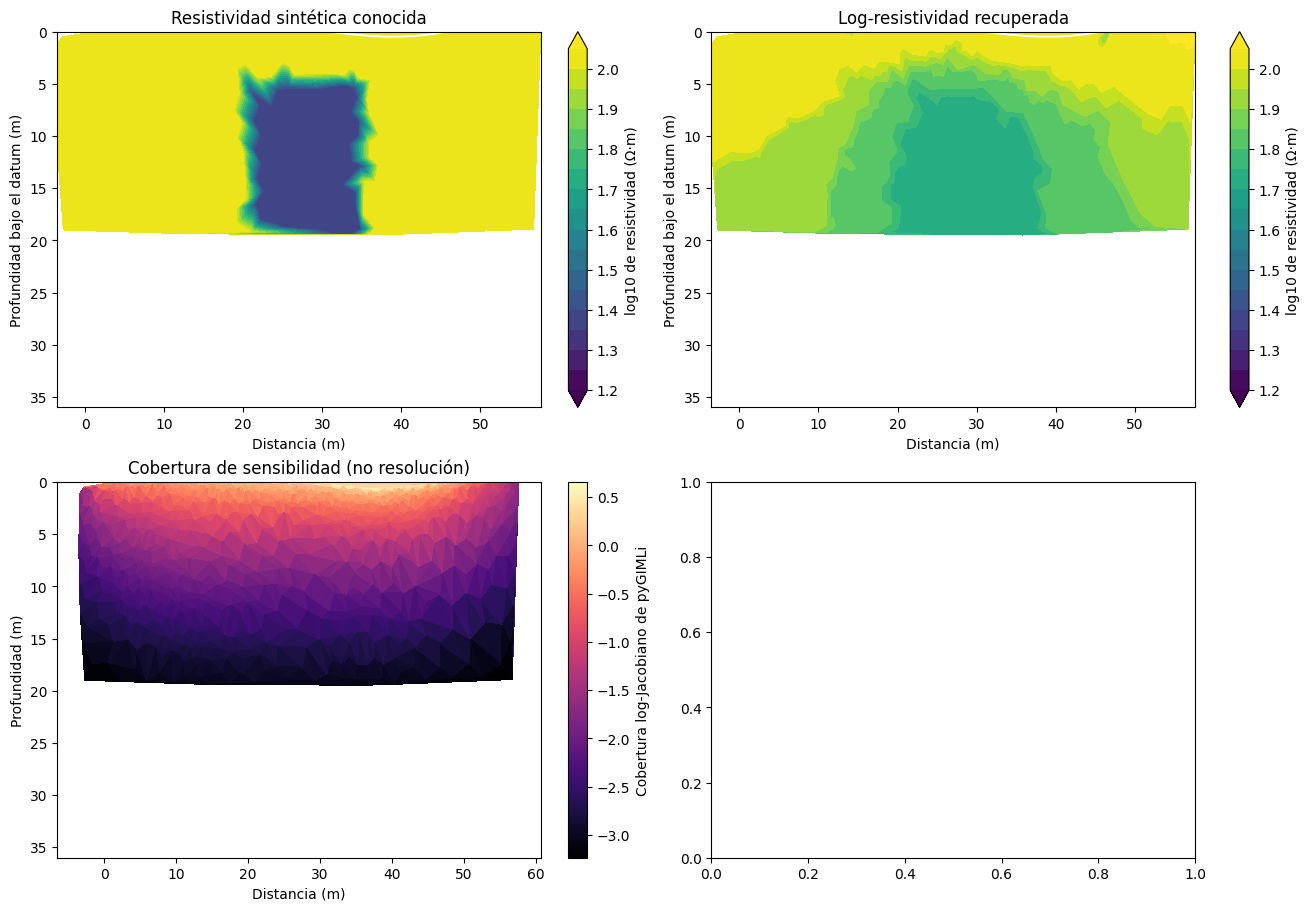

In [10]:
# Grafique la verdad sintética conocida, el modelo recuperado y la cobertura de sensibilidad.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for axis, values, title in (
    (ax[0, 0], truth, "Resistividad sintética conocida"),
    (ax[0, 1], model, "Log-resistividad recuperada"),
):
    image = axis.tricontourf(
        tri,
        np.log10(values) if values is truth else model_log10_display,
        levels=np.linspace(1.2, 2.05, 18),
        cmap="viridis",
        extend="both",
    )
    fig.colorbar(image, ax=axis, label="log10 de resistividad (Ω·m)")
    electrode_x = experiment["experiment"]["geometry"]["electrode_x_m"]
    electrode_z = experiment["experiment"]["geometry"]["electrode_z_m"]
    axis.plot(electrode_x, -np.asarray(electrode_z), color="white", lw=1.4)
    axis.set(title=title, xlabel="Distancia (m)", ylabel="Profundidad bajo el datum (m)", ylim=(36, 0))
image = ax[1, 0].tripcolor(tri, coverage, shading="flat", cmap="magma")
fig.colorbar(image, ax=ax[1, 0], label="Cobertura log-Jacobiano de pyGIMLi")
ax[1, 0].set(
    title="Cobertura de sensibilidad (no resolución)",
    xlabel="Distancia (m)",
    ylabel="Profundidad (m)",
    ylim=(36, 0),
)


El diagrama separa filas ajustadas y reservadas y muestra residuales logarítmicos con signo frente al punto medio de adquisición. Una estructura espacial en los puntos retenidos revelaría error predictivo que un RMSE agregado oculta. Son residuales de una malla sintética con semilla y un modelo de ruido; evalúan esa partición, no precisión de campo ni unicidad geológica.


In [11]:
# Grafique los residuales con signo por punto medio de adquisición e informe las puntuaciones independientes.
ax[1, 1].scatter(
    midpoints[train],
    np.round(np.log(predicted[train] / observed[train]), 3),
    s=18,
    label="ajuste",
    alpha=0.75,
)
ax[1, 1].scatter(
    midpoints[held],
    np.round(np.log(predicted[held] / observed[held]), 3),
    s=30,
    label="retenido",
    alpha=0.9,
)
ax[1, 1].axhline(0, color="black", lw=0.8)
ax[1, 1].set(
    title="Residual con signo de log-resistencia",
    xlabel="AB midpoint (m)",
    ylabel="ln(predicho / observado)",
)
ax[1, 1].legend()
fig.suptitle("ERT 2D topográfica · control sintético · no es geología de campo", fontsize=14)
plt.show()


### Leer las métricas de la inversa sintética

El panel de residuos anterior se indexa por punto medio de adquisición y distingue filas de entrenamiento y reserva. Estas métricas informan estado de la inversa, tamaño del modelo, error respecto de la verdad, mejoras en reserva y pruebas de sensibilidad del mismo experimento recién calculado.

El panel del modelo agrupa log10 de resistividad en intervalos de 0,1 para estabilizar las categorías visuales; el modelo y la cobertura con precisión completa permanecen en el recibo. Los errores impresos usan tres decimales porque las ejecuciones repetidas de pyGIMLi varían por debajo de esa precisión informada.

La variación de píxeles se limita mediante una tolerancia PNG declarada: como máximo 0,05 % de píxeles distintos y error absoluto medio normalizado 0,0002. Se compararon la figura guardada y la recién calculada; el recibo numérico completo sigue siendo el registro científico.

In [12]:
# Leer las métricas de la inversa sintética.
print("estado de la inversa", experiment["inverse_status"])
print("celdas de parámetros", inv["mesh_cells"])
print(
    "RMSE celda a celda frente a verdad log10 =",
    round(experiment["synthetic_truth_comparison"]["log10_rmse_over_parameter_cells"], 3),
)
print("mejora retenida intercalada", round(inv["heldout_improvement_vs_homogeneous"], 3))
print("mejora retenida por bloques", round(experiment["blocked_validation"]["improvement_vs_homogeneous"], 3))
print(
    "RMSE log retenido con malla alternativa =",
    round(experiment['sensitivity']["alternate_mesh"]["heldout_log_r_rmse"], 3),
)
print(
    "RMSE log retenido con error duplicado =",
    round(experiment['sensitivity']["doubled_assumed_error"]["heldout_log_r_rmse"], 3),
)


estado de la inversa passed
celdas de parámetros 835
RMSE celda a celda frente a verdad log10 = 0.121
mejora retenida intercalada 0.657
mejora retenida por bloques 0.558
RMSE log retenido con malla alternativa = 0.031
RMSE log retenido con error duplicado = 0.029


Repita QC del producto antes de interpretar la inversa física.

In [13]:
# Repita QC del producto antes de interpretar la inversa física.
qc_repeat = ert.qc(s)
print("indicadores:", qc_repeat["flagged_rows"], "relief m:", qc_repeat["topographic_relief_m"])


indicadores: [5] relief m: 0.639031


Recalcule factores analíticos planos para las mismas lecturas sintéticas.

In [14]:
# Recalcule factores analíticos planos para las mismas lecturas sintéticas.
flat_factors = ert.flat_halfspace_factors(s)
print("rango del factor m:", float(flat_factors.min()), float(flat_factors.max()))


rango del factor m: 12.566370614359172 37.69911184307752


Recalcule la reserva congelada por separación.

In [15]:
# Recalcule la reserva congelada por separación.
train_rows, held_rows = ert.holdout_indices(s)
print("entrenamiento:", len(train_rows), "retenido:", len(held_rows))


entrenamiento: 25 retenido: 5


## Resultados

Las reservas intercalada y espacial responden preguntas distintas: la primera interpola entre cuadripolos omitidos y la segunda desafía transferencia a través de la línea. El RMSE logarítmico bloqueado es mayor, y la cobertura del Jacobiano es sensibilidad, no resolución espacial. Malla y error cambian poco en este caso generado por elementos finitos; ningún resultado se transfiere a los datos Slagdump ausentes.

**Respuesta:** La ejecución M07 pasó con 82 mediciones y 835 celdas paramétricas. El RMSE de log-resistencia reservada es 0.03129 para la partición intercalada y 0.06564 para bloques espaciales; el RMSE de verdad log10 por celda es 0.1208. Malla alternativa y error duplicado dan 0.0315 y 0.0288.


## Resumen

Pasan los controles sintéticos, aunque el bloqueo espacial casi duplica el error reservado intercalado. Es una prueba con verdad sintética de elementos finitos; no habilita el caso Slagdump, cuyo `.ohm` crudo sigue ausente.



## Referencias

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)